# 4 · Grad-CAM: which lasers × freqs drive the mask
The input as an image: 100 lasers (10×10 wall grid) × 1170 freq bins (100-1000 Hz), 2 channels summed. Three attributions on the eval subset of `00_setup`:
- **Grad-CAM** (`pytorch_grad_cam`, jacobgil): on the last freq block's tokens, one per (laser, 64-bin band) = a 100×19 "image"; `reshape_transform` turns the (B·L, 19, d) tokens into (B, d, L, 19), the input is fed as (B, C, L, F), so the lib's resize maps 100×19 → 100×1170: laser rows stay exact and only the 19 bands are interpolated along freq (no 10×10 → image stretch). The lib also min-max scales each sample, so its absolute values aren't comparable across samples; we only use per-sample shares.
- **HiResCAM** (hand-written, ~4 lines): grads × acts summed over d on the last *laser*-stage block (100 tokens → 10×10), relu, no resize; laser-only, no freq axis.
- **grad × input** and **integrated gradients** (16 steps) on the per-box *normalized* input, baseline 0 = the train mean (as nb104), |·| summed over channels.

**Target:** the predicted mask logits summed inside the predicted mask (p > 0.08): "what keeps the model painting what it paints", one scalar per sample, no class needed; samples with an empty prediction are skipped. Each sample's map is scaled to sum 1 before averaging, so every sample counts once.

In [1]:
%run ./00_setup.ipynb

s9-transformer-vase-1k 1000ep cuda (9703981056, 16608133120)


2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

split
train                                       1000
eval/gastro/cube-unseen-speaker-baseline      40
eval/gastro/cube                              40
eval/gastro/vase                              40
eval/gastro/unseen-position                   40
Name: count, dtype: int64 3178 samples, 66 splits
(3178, 100, 1170, 2) (3178, 64, 64)


<All keys matched successfully>
L=100 (10x10), 19 bands of 64 bins ~49 Hz


          iou@0.08  miss@0.08  iou@0.5  soft_iou  com_err
is_train                                                 
False        0.464      0.139    0.458     0.458    0.072
True         0.911      0.004    0.977     0.911    0.004


iou@0.08 here vs run's saved eval (same splits, subset): 0.441 vs 0.441, per-split corr 1.00


In [2]:
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM

class Wrap(torch.nn.Module):   # the lib wants module(tensor) -> per-sample outputs; input (B,C,L,F) so the cam is resized to (L,F)
    def __init__(s, m): super().__init__(); s.m = m
    def forward(s, x): return s.m({"fft": x.permute(0, 2, 3, 1), "box": s.box})["mask_logits"]
wrap = Wrap(model).eval()
cam = GradCAM(wrap, target_layers=[model.encoder.freq_enc.freqs[-1]], reshape_transform=lambda a: a.view(-1, L, *a.shape[1:]).permute(0, 3, 1, 2))  # (B*L,19,d) -> (B,d,L,19)

enc = model.encoder
def head(xn, box):   # normalized (B,L,F,C) -> (B,64,64) mask logits, the encoder without its normalize
    laser = enc.laser_emb + enc.laser_pos(enc.laser_fourier)
    return model.decoder(enc.laser_enc(enc.freq_enc(xn, box, enc.freq_band_logf, laser), laser))[:, 0]
def grads(xn, box, M): xn = xn.detach().requires_grad_(); return torch.autograd.grad((head(xn, box) * M).sum(), xn)[0]
STEPS = 16

ACT = {}
enc.laser_enc.lasers[-1].register_forward_hook(lambda m, i, o: ACT.update(a=o))   # laser-stage tokens (B,100,d)
def hirescam(x, box, M):   # HiResCAM by hand: sum_d grad*act per laser token, relu, no resize -> (B,100)
    lo = model({"fft": x, "box": box})["mask_logits"]
    a = ACT["a"]; return (torch.autograd.grad((lo * M).sum(), a)[0] * a).sum(-1).relu()

In [3]:
# fp32 on the GPU, batches of 16; every map (B,L,F) scaled to sum 1 per sample
EV = np.flatnonzero(~df.is_train.values)
METHODS = ["gradcam", "gxi", "ig"]
S = {k: np.zeros((L, len(FREQS))) for k in METHODS}
HR = np.zeros(L); EX = {}; n_ok = 0
norm = lambda a: a / a.sum((1, 2), keepdims=True).clip(1e-12)
for s in range(0, len(EV), 16):
    j = EV[s:s + 16]
    x, box = xb(j), BOX[j].to(DEV)
    with torch.no_grad(): M = (model({"fft": x, "box": box})["mask_logits"].sigmoid() > THR).float()
    ok = M.flatten(1).any(1).cpu().numpy()
    wrap.box = box
    gc = cam(x.permute(0, 3, 1, 2), targets=[lambda o, m=m: (o * m).sum() for m in M])              # (B,L,F) in [0,1]
    xn = enc.normalize(x, box)
    gxi = (grads(xn, box, M) * xn).abs().sum(-1)
    ig = (sum(grads(a * xn, box, M) for a in (torch.arange(STEPS, device=DEV) + 0.5) / STEPS) / STEPS * xn).abs().sum(-1)
    hr = hirescam(x, box, M).detach().cpu().numpy(); HR += (hr / hr.sum(1, keepdims=True).clip(1e-12))[ok].sum(0)
    maps = dict(gradcam=norm(gc), gxi=norm(gxi.detach().cpu().numpy()), ig=norm(ig.detach().cpu().numpy()))
    for k, a in maps.items():
        S[k] += a[ok].sum(0)
    for b, i in enumerate(j):
        if ok[b] and df.split.iloc[i] not in EX and len(EX) < 64: EX[df.split.iloc[i]] = (i, {k: a[b] for k, a in maps.items()}, M[b].cpu().numpy())
    n_ok += ok.sum()
MAP = {k: v / n_ok for k, v in S.items()}
LM = ["gradcam", "hirescam", "gxi", "ig"]                       # laser-level methods
LAS = {k: MAP[k].sum(1) for k in METHODS} | {"hirescam": HR / n_ok}
print(f"{n_ok}/{len(EV)} eval samples with a non-empty predicted mask")

2102/2178 eval samples with a non-empty predicted mask


### Average laser × freq map (eval set)
Rows = laser index (row·10 + col), columns = freq. Each method's colour scale is its own (99th pct).

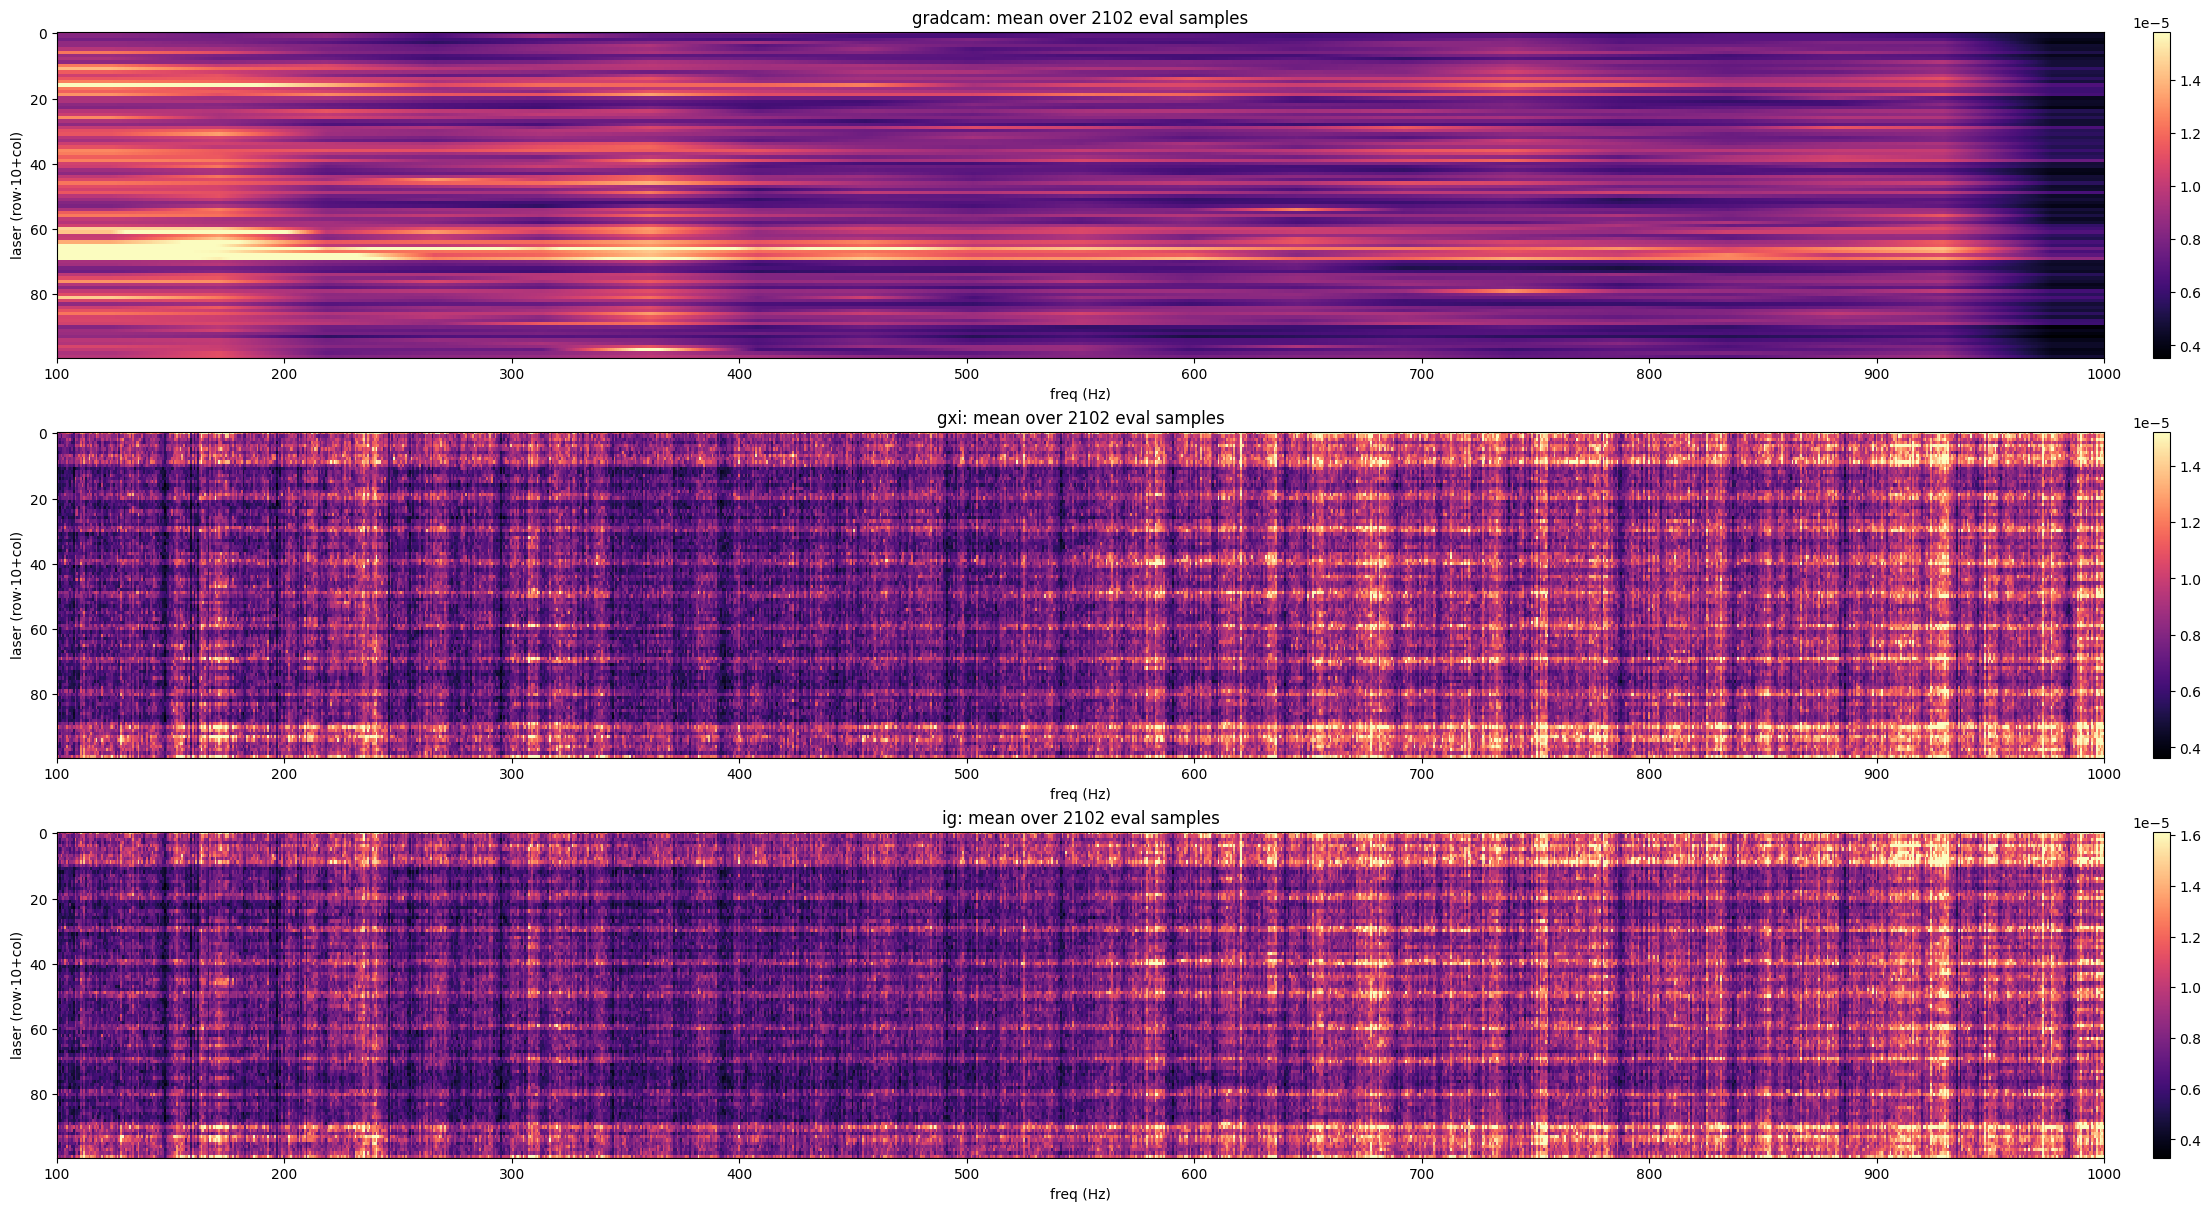

In [4]:
fig, axs = plt.subplots(len(METHODS), 1, figsize=(22, 4 * len(METHODS)), constrained_layout=True)
for ax, k in zip(axs, METHODS):
    im = ax.imshow(MAP[k], aspect="auto", cmap="magma", vmax=np.percentile(MAP[k], 99), extent=[FREQS[0], FREQS[-1], L - 0.5, -0.5], interpolation="nearest")
    ax.set(title=f"{k}: mean over {n_ok} eval samples", xlabel="freq (Hz)", ylabel="laser (row·10+col)"); fig.colorbar(im, ax=ax, pad=0.005)
plt.show()

### Laser marginal on the 2D laser grid
Sum over freq, shown on the 10×10 grid (laser l at row l // 10, col l % 10, the dataset's convention; row 0 is the `grid_coords` top row). Dashed line = uniform (1/100).

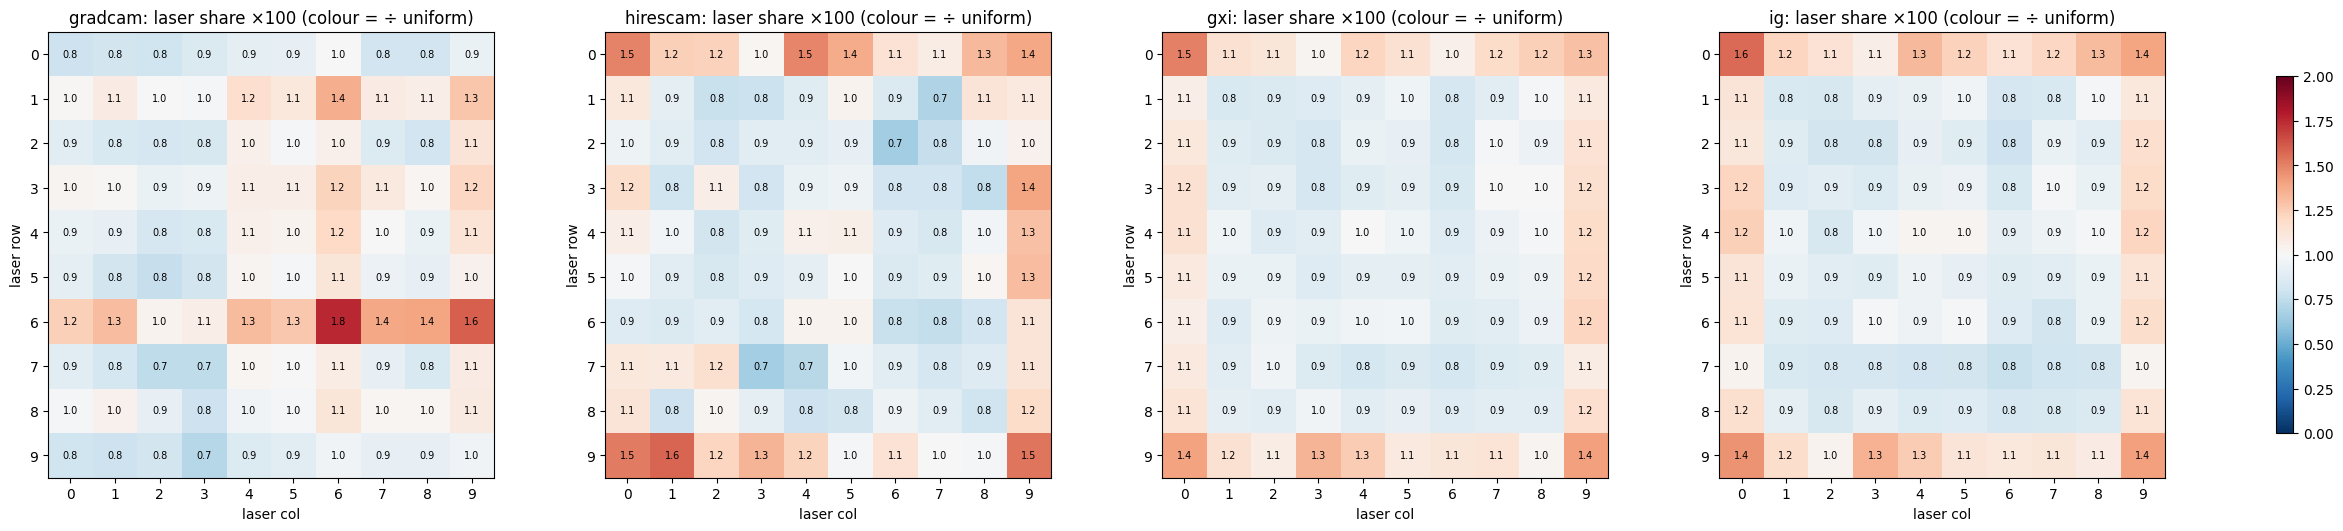

In [5]:
fig, axs = plt.subplots(1, len(LM), figsize=(6 * len(LM), 5.2), constrained_layout=True)
for ax, k in zip(axs, LM):
    g = LAS[k].reshape(R, Cc)
    im = ax.imshow(g / g.mean(), cmap="RdBu_r", vmin=0, vmax=2)
    for r in range(R):
        for c in range(Cc): ax.text(c, r, f"{g[r, c] * 100:.1f}", ha="center", va="center", fontsize=7)
    ax.set(title=f"{k}: laser share ×100 (colour = ÷ uniform)", xlabel="laser col", ylabel="laser row", xticks=range(Cc), yticks=range(R))
fig.colorbar(im, ax=axs, shrink=0.8); plt.show()

### Freq marginal
Sum over lasers, per bin (thin) and per 64-bin model band (steps). Grad-CAM is band-resolution by construction.

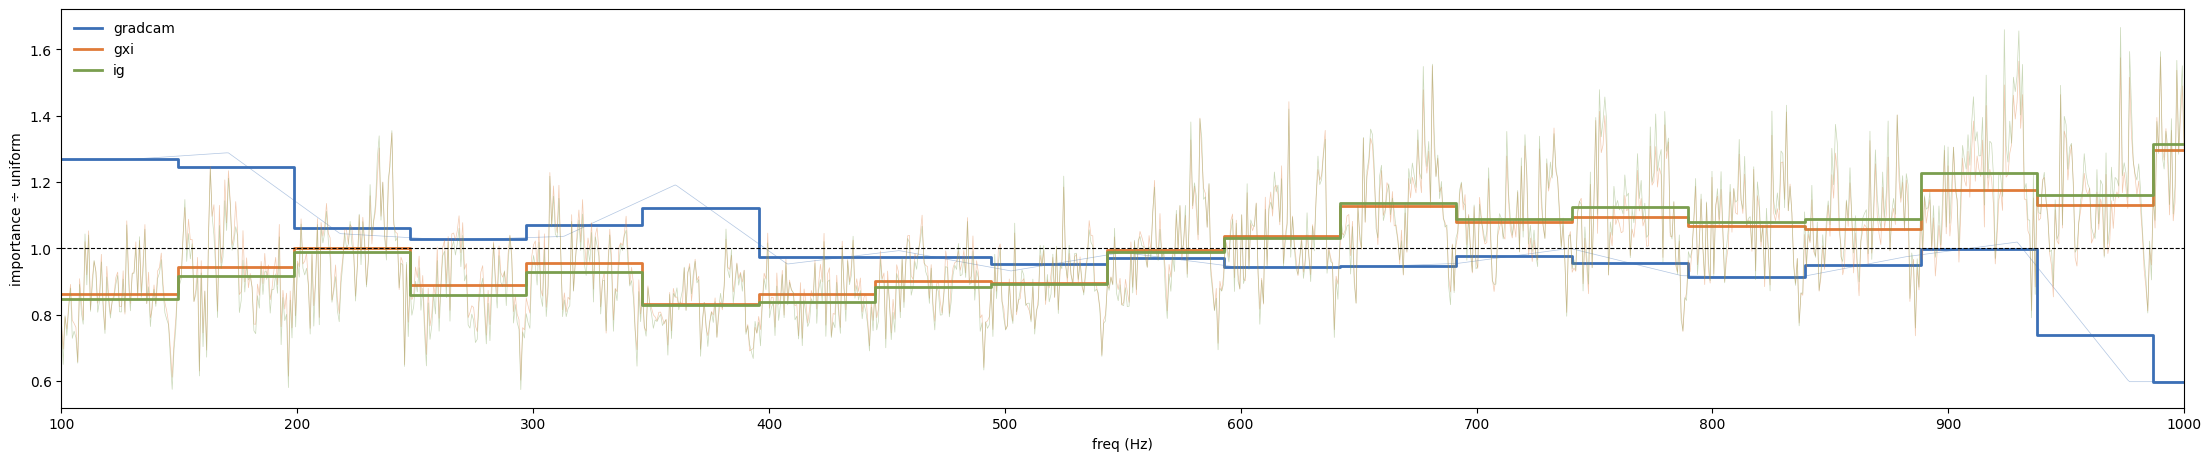

In [6]:
fig, ax = plt.subplots(figsize=(22, 4.5), constrained_layout=True)
band = lambda f: np.add.reduceat(f, np.arange(0, len(f), BPB)) / np.diff(np.r_[np.arange(0, len(f), BPB), len(f)])
for k, col in zip(METHODS, ["#3B6FB6", "#E07B39", "#7A9E4E"]):
    f = MAP[k].sum(0) * len(FREQS)                      # 1 = uniform
    ax.plot(FREQS, f, color=col, lw=0.5, alpha=0.4)
    ax.step(np.r_[FREQS[::BPB], FREQS[-1]], np.r_[band(f), band(f)[-1]], where="post", color=col, lw=2, label=k)
ax.axhline(1, color="k", ls="--", lw=0.8); ax.set(xlabel="freq (Hz)", ylabel="importance ÷ uniform", xlim=(FREQS[0], FREQS[-1])); ax.legend(frameon=False)
plt.show()

In [7]:
# top lasers / bands per method
rows = []
for k in LM:
    lz, fz = LAS[k], band(MAP[k].sum(0) * len(FREQS)) if k in MAP else np.zeros(0)
    tl, tb = np.argsort(-lz)[:8], np.argsort(-fz)[:5]
    rows.append(dict(method=k, top_lasers=", ".join(f"({l // Cc},{l % Cc}) {lz[l] * 100:.1f}%" for l in tl),
                     top_bands=", ".join(f"{FREQS[b * BPB]:.0f}-{FREQS[min(b * BPB + BPB, len(FREQS)) - 1]:.0f}Hz ×{fz[b]:.2f}" for b in tb)))
pd.set_option("display.max_colwidth", 200); display(pd.DataFrame(rows).set_index("method"))
lm = pd.DataFrame(LAS)[LM]; print("laser-marginal Spearman between methods:\n", lm.corr("spearman").round(2))

,top_lasers,top_bands
method,,
gradcam,"(6,6) 1.8%, (6,9) 1.6%, (6,8) 1.4%, (6,7) 1.4%, (1,6) 1.4%, (6,4) 1.3%, (6,1) 1.3%, (1,9) 1.3%","100-149Hz ×1.27, 149-198Hz ×1.25, 346-395Hz ×1.12, 297-346Hz ×1.07, 199-247Hz ×1.06"
hirescam,"(9,1) 1.6%, (9,9) 1.5%, (9,0) 1.5%, (0,0) 1.5%, (0,4) 1.5%, (3,9) 1.4%, (0,9) 1.4%, (0,5) 1.4%",
gxi,"(0,0) 1.5%, (9,9) 1.4%, (9,0) 1.4%, (9,3) 1.3%, (0,9) 1.3%, (9,4) 1.3%, (0,8) 1.2%, (6,9) 1.2%","987-1000Hz ×1.30, 888-937Hz ×1.18, 938-986Hz ×1.13, 642-691Hz ×1.13, 741-789Hz ×1.09"
ig,"(0,0) 1.6%, (9,0) 1.4%, (9,9) 1.4%, (0,9) 1.4%, (9,3) 1.3%, (0,4) 1.3%, (0,8) 1.3%, (9,4) 1.3%","987-1000Hz ×1.31, 888-937Hz ×1.23, 938-986Hz ×1.16, 642-691Hz ×1.14, 741-789Hz ×1.12"


laser-marginal Spearman between methods:
           gradcam  hirescam   gxi    ig
gradcam      1.00     -0.23 -0.20 -0.13
hirescam    -0.23      1.00  0.79  0.76
gxi         -0.20      0.79  1.00  0.93
ig          -0.13      0.76  0.93  1.00


### Per-sample examples
True mask, predicted mask (p > 0.08), and each method's laser marginal on the grid + its laser × freq map.

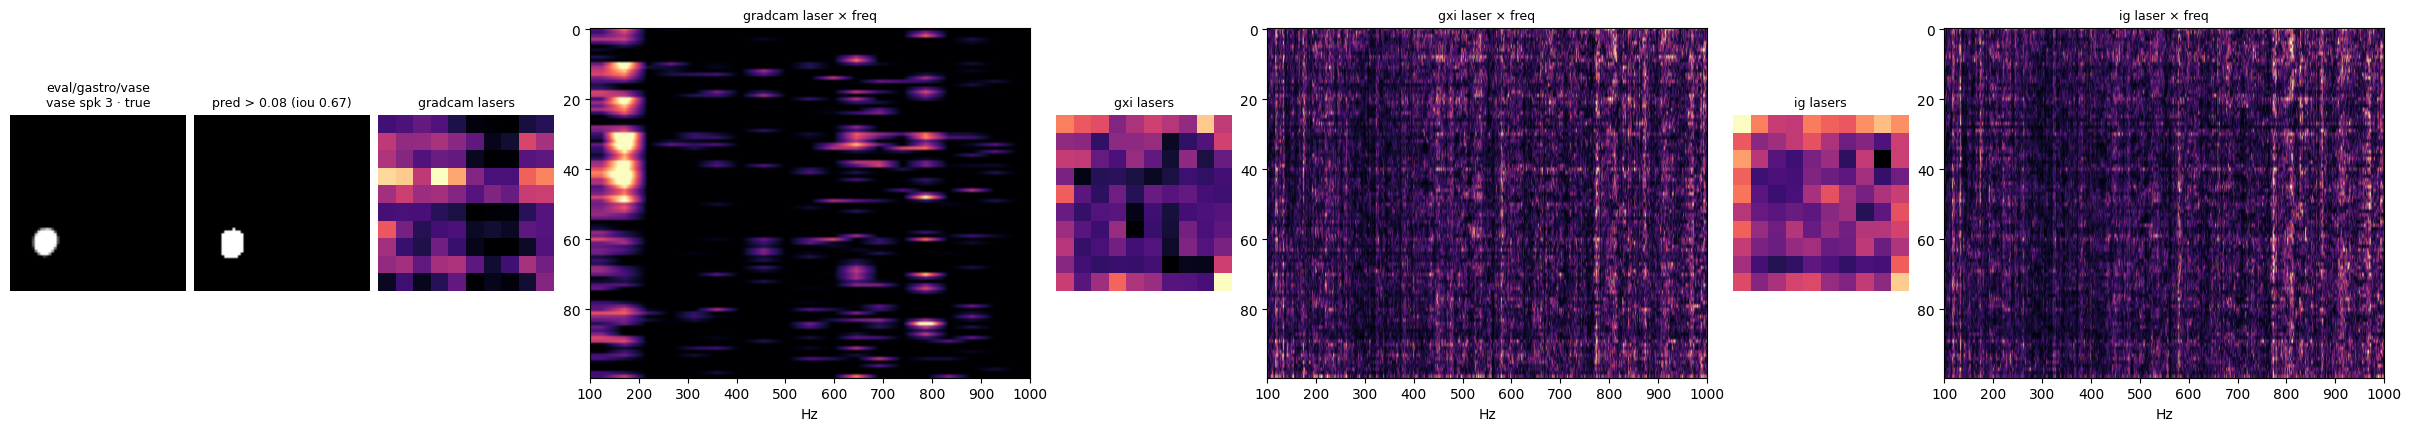

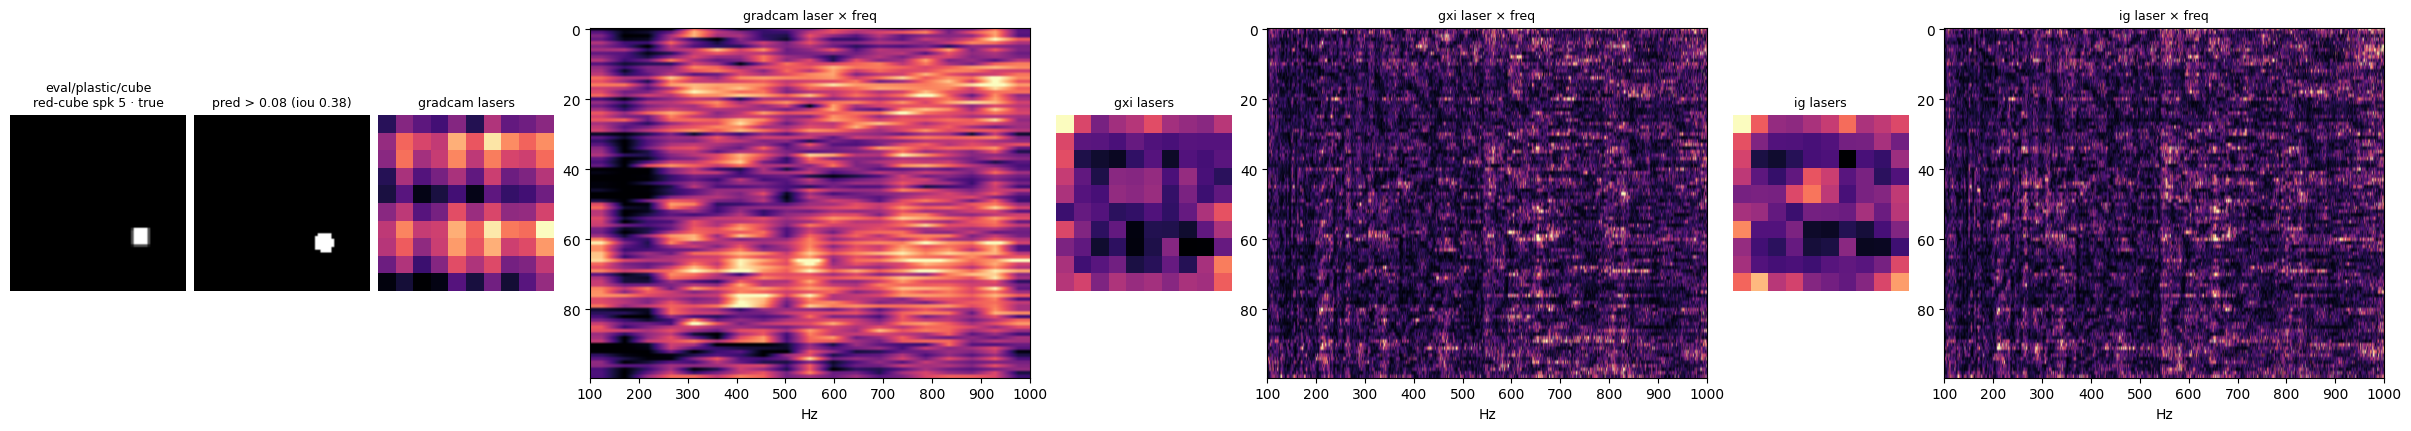

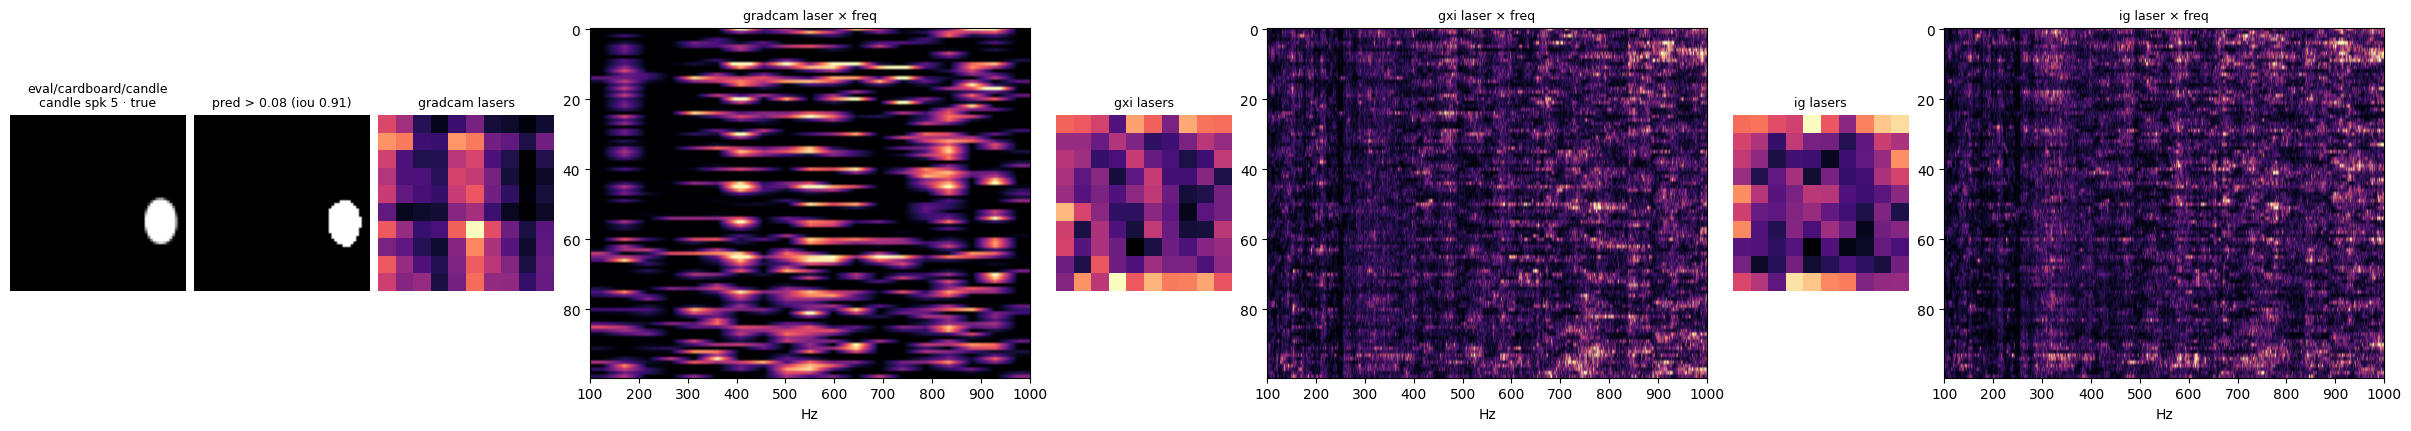

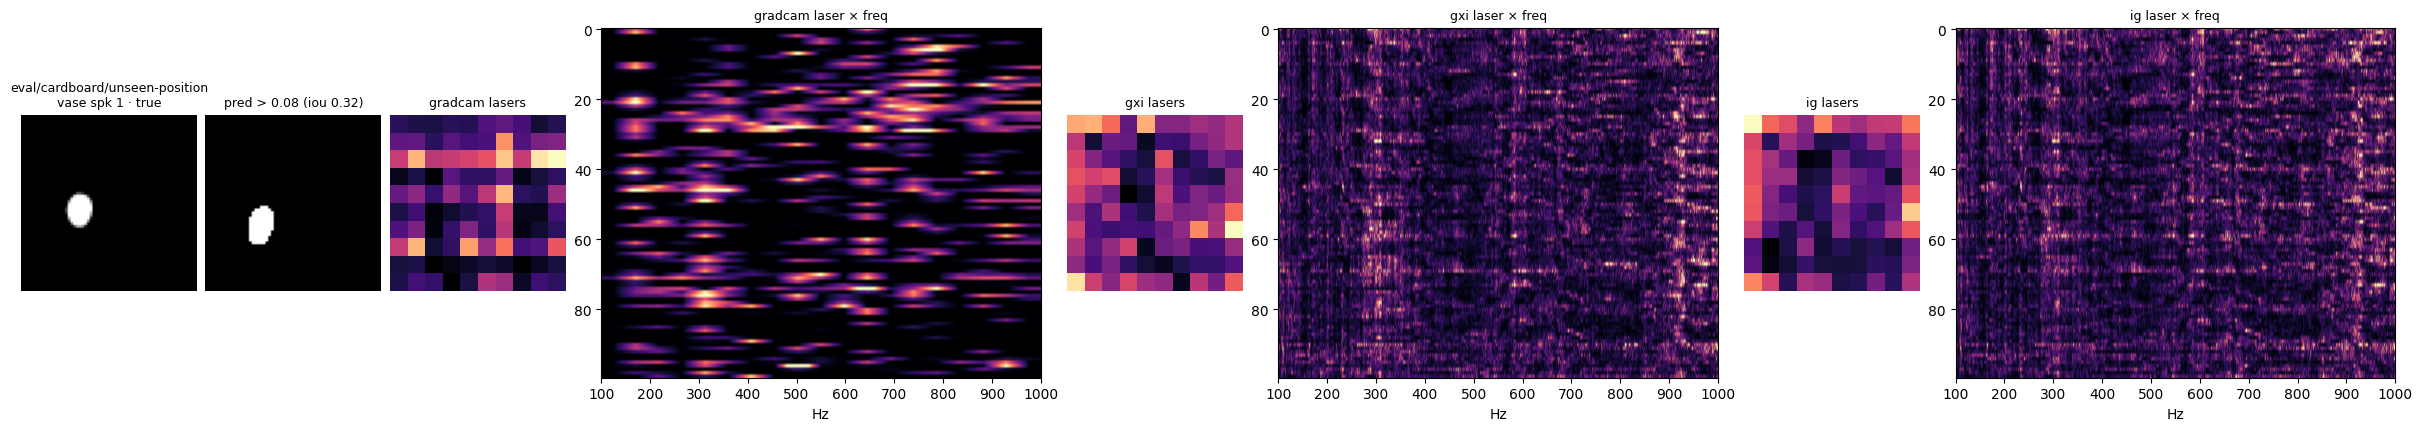

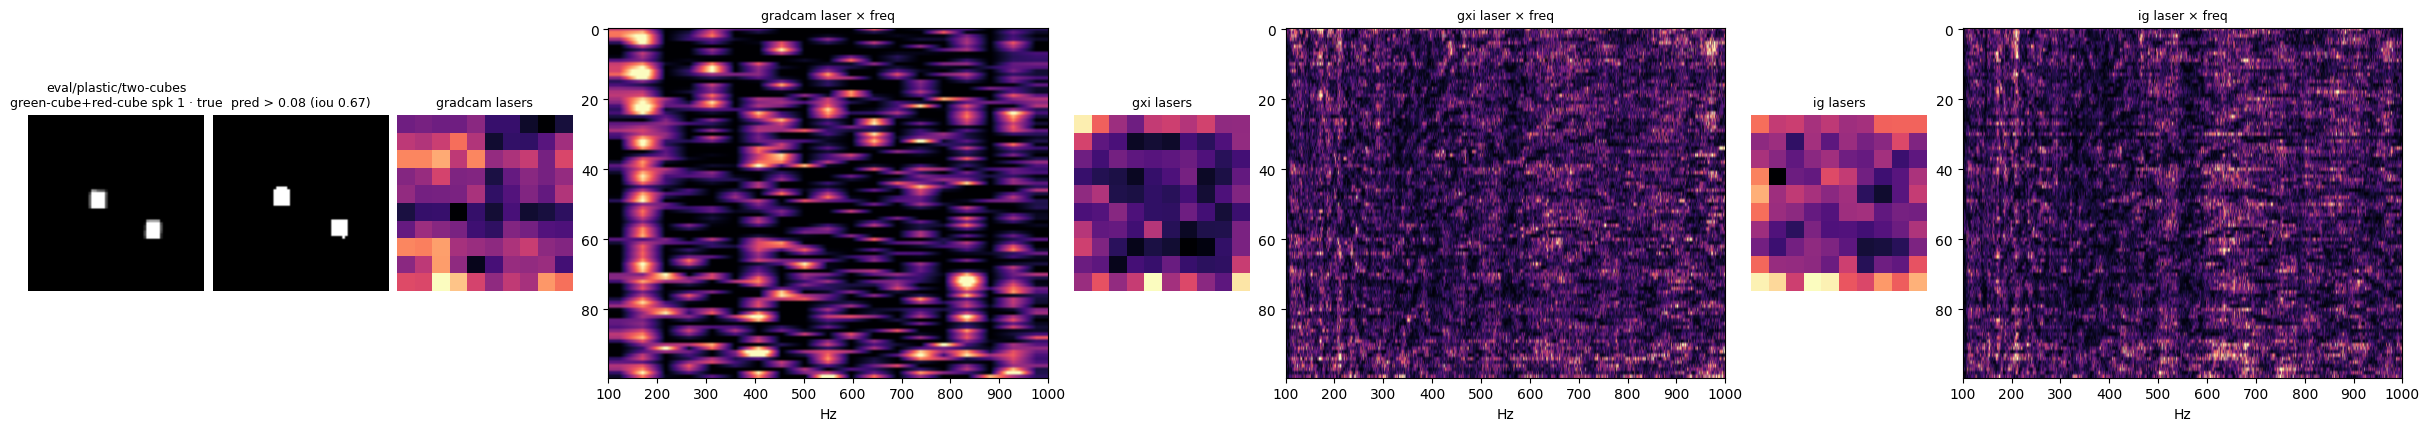

In [8]:
from PIL import Image
want = ["eval/gastro/vase", "eval/plastic/cube", "eval/cardboard/candle", "eval/cardboard/unseen-position", "eval/plastic/two-cubes"]
for sp in [w for w in want if w in EX]:
    i, maps, m = EX[sp]
    fig = plt.figure(figsize=(24, 4.2), constrained_layout=True); gs = fig.add_gridspec(1, 2 + 2 * len(METHODS), width_ratios=[1, 1] + [1, 2.5] * len(METHODS))
    a = fig.add_subplot(gs[0]); a.imshow(Y[i], cmap="gray"); a.set_title(f"{sp}\n{df.object.iloc[i]} spk {df.speaker.iloc[i]} · true", fontsize=9); a.axis("off")
    a = fig.add_subplot(gs[1]); a.imshow(m, cmap="gray"); a.set_title(f"pred > {THR} (iou {df[METRIC].iloc[i]:.2f})", fontsize=9); a.axis("off")
    for n, k in enumerate(METHODS):
        a = fig.add_subplot(gs[2 + 2 * n]); a.imshow(maps[k].sum(1).reshape(R, Cc), cmap="magma"); a.set_title(f"{k} lasers", fontsize=9); a.axis("off")
        a = fig.add_subplot(gs[3 + 2 * n]); a.imshow(maps[k], aspect="auto", cmap="magma", vmax=np.percentile(maps[k], 99.5), extent=[FREQS[0], FREQS[-1], L - 0.5, -0.5])
        a.set_title(f"{k} laser × freq", fontsize=9); a.set_xlabel("Hz")
    plt.show()

In [9]:
out = ROOT / "notebooks/drafts_114/imp_gradcam.npz"
np.savez(out, **{f"laser_{k}": LAS[k] for k in LM}, **{f"freq_{k}": MAP[k].sum(0) for k in METHODS},
         **{f"map_{k}": MAP[k].astype(np.float32) for k in METHODS}, freqs=FREQS, n=n_ok)
print(out, sorted(np.load(out).files))

/home/ethantu/workspace/good-vibrations/notebooks/drafts_114/imp_gradcam.npz ['freq_gradcam', 'freq_gxi', 'freq_ig', 'freqs', 'laser_gradcam', 'laser_gxi', 'laser_hirescam', 'laser_ig', 'map_gradcam', 'map_gxi', 'map_ig', 'n']


**Findings (2102/2178 eval samples).** Every map is close to flat: the top laser holds ~1.6-1.8 % against 1 % uniform, and the top band is ×1.3. Nothing dominates, the same as nb104's occlusion result.
- **Grad-CAM** (band tokens, last freq block): laser row 6 stands out, (6,6) peaks, and the low bands 100-200 Hz are strongest, then 300-400 Hz. Per sample it is sparse, a few (laser, band) blobs.
- **HiResCAM** (laser stage, 10×10): border/corner lasers, (9,1), (9,9), (9,0), (0,0) ~1.5 %; agrees with grad×input / IG (Spearman 0.79 / 0.76), not with the freq-stage Grad-CAM (−0.23). It uses no input scaling, so the border preference is not only an |x| effect. The one outlier is the library's band-level Grad-CAM (global channel weights + per-sample min-max).
- **grad×input / IG** agree (laser Spearman 0.93) but disagree with Grad-CAM (≈ −0.2). They favour the grid's border lasers (corners (0,0), (9,9), (9,0), (0,9)) and the top of the sweep, 890-1000 Hz. Both scale by the normalized input |x|, so they also weight where the input deviates most from the train mean. The border and band-edge bins may just be noisier (nb95/nb100), so read them as "input × sensitivity", not as pure sensitivity.